In [1]:
import math
import numpy as np
from scipy.optimize import minimize
from scipy.special import softmax


def forecast_ev(records, end_year=2035, fleet_growth=0., check=lambda *_: None):
    """Multinomial shares, chronological selection, and empirical backtest errors."""
    records = sorted(records, key=lambda r: int(r["year"]))
    if len(records) < 6:
        raise ValueError("Insufficient history: at least six comparable annual observations are required. Import a separately labeled parent-area series.")
    years = np.array([int(r["year"]) for r in records])
    if np.any(np.diff(years) != 1):
        raise ValueError("History must have consecutive, unique years; reporting gaps cannot be filled silently")
    if len({(r.get("geographyId"), r.get("geographyLevel")) for r in records}) != 1:
        raise ValueError("Select one geographic series; do not pool counties or geographic levels")
    if any(r.get("reportingBreak") or r.get("suppressed") for r in records):
        raise ValueError("Remove or reconcile reporting breaks/suppressed observations before forecasting")
    fleet = np.array([float(r["total"]) for r in records])
    bev, phev = np.array([float(r["bev"]) for r in records]), np.array([float(r["phev"]) for r in records])
    if not np.all(np.isfinite(np.concatenate([fleet, bev, phev]))) or np.any(fleet <= 0) or np.any(bev < 0) or np.any(phev < 0) or np.any(bev + phev > fleet):
        raise ValueError("Vehicle counts must be finite, nonnegative, and not exceed their matching total")
    counts = np.column_stack([bev, phev, fleet - bev - phev])
    end_year = int(end_year)
    if end_year <= years[-1] or end_year > 2050 or not -0.2 <= float(fleet_growth) <= 0.2:
        raise ValueError("Forecast year must follow history and be at most 2050; fleet growth must be between -20% and 20%")

    def fit(n):
        # Use all supplied comparable years. A small ridge penalty stabilizes zero classes.
        x = np.column_stack([np.ones(n), years[:n] - years[0]])
        c = counts[:n]
        def objective(flat):
            beta = flat.reshape(2, 2)
            logits = np.column_stack([x @ beta, np.zeros(n)])
            probs = np.clip(softmax(logits, axis=1), 1e-12, 1.)
            return -float(np.sum(c * np.log(probs)) / fleet[:n].sum()) + 1e-5 * float(np.sum(beta[1] ** 2))
        result = minimize(objective, np.array([[-4., -4.], [0.1, 0.1]]).ravel(), method="BFGS")
        if not np.all(np.isfinite(result.x)):
            raise ValueError("EV trend fitting failed")
        return result.x.reshape(2, 2)

    errors = {"multinomial_trend": [], "last_observed_share": []}
    backtests = []
    for n in range(4, len(records)):
        check(n / len(records))
        beta = fit(n)
        for horizon in range(1, min(3, len(records) - n) + 1):
            j = n + horizon - 1
            predictions = {
                "multinomial_trend": softmax(np.r_[np.array([1., years[j] - years[0]]) @ beta, 0.]),
                "last_observed_share": counts[n - 1] / fleet[n - 1],
            }
            for model, shares in predictions.items():
                residual = counts[j, :2] - shares[:2] * fleet[j]
                errors[model].append((residual / fleet[j]).tolist())
                backtests.append({"model": model, "trainThrough": int(years[n - 1]), "year": int(years[j]),
                                  "horizon": horizon, "actualBev": float(bev[j]), "actualPhev": float(phev[j]),
                                  "predictedBev": float(shares[0] * fleet[j]), "predictedPhev": float(shares[1] * fleet[j])})
    scores = {k: float(np.mean(np.abs(v))) for k, v in errors.items()}
    selected = min(scores, key=lambda k: (scores[k], k))
    beta = fit(len(records))
    residuals = np.abs(np.asarray(errors[selected]))
    width = np.quantile(residuals, .8, axis=0) if len(residuals) >= 5 else None
    rows = []
    for year in range(int(years[-1]) + 1, end_year + 1):
        h = year - years[-1]
        future_fleet = float(fleet[-1] * (1 + float(fleet_growth)) ** h)
        for scenario, multiplier in (("slower", .75), ("baseline", 1.), ("faster", 1.25)):
            if selected == "multinomial_trend":
                logits = np.array([1., years[-1] - years[0]]) @ beta + h * multiplier * beta[1]
                shares = softmax(np.r_[logits, 0.])
            else:
                shares = counts[-1] / fleet[-1]
            for index, vehicle in enumerate(("BEV", "PHEV", "OTHER")):
                value = float(shares[index] * future_fleet)
                row = {"year": year, "scenario": scenario, "vehicle": vehicle, "count": value,
                       "share": float(shares[index]), "total": future_fleet, "kind": "forecast", "geographyId": records[-1].get("geographyId"),
                       "intervalInterpretation": "Extrapolated beyond validated horizons" if h > 3 else "Empirical backtest error envelope; not a calibrated probability interval"}
                if width is not None and index < 2:
                    spread = float(width[index] * future_fleet * math.sqrt(h))
                    row.update(lower=max(0., value - spread), upper=min(future_fleet, value + spread))
                rows.append(row)
    history = [{"year": int(y), "vehicle": v, "count": float(counts[i, j]), "share": float(counts[i, j] / fleet[i]),
                "total": float(fleet[i]), "kind": "observed", "scenario": "observed", "geographyId": records[i].get("geographyId")} for i, y in enumerate(years) for j, v in enumerate(("BEV", "PHEV", "OTHER"))]
    return {"rows": history + rows, "backtests": backtests, "model": selected, "selectionErrors": scores,
            "assumptions": {"fleetGrowth": float(fleet_growth), "endYear": end_year, "trendMultipliers": [.75, 1., 1.25],
                            "geography": records[-1].get("geographyLevel"), "chargingDemand": "Not inferred"},
            "modelCard": {"status": "experimental", "method": "Multinomial time trend versus last-observed-share, rolling 1–3 year holdouts",
                          "trainingYears": years.tolist(), "sources": [r.get("sourceUrl") for r in records if r.get("sourceUrl")],
                          "uncertainty": "Error envelopes describe historical errors; 2035 values are scenario extrapolations"}}


def pv_capacity(area, efficiency=.2, tilt=0.):
    if not all(math.isfinite(float(x)) for x in (area, efficiency, tilt)) or area < 0 or not 0 < efficiency <= 1 or not 0 <= tilt < 85:
        raise ValueError("PV area, efficiency, or tilt is invalid")
    module_area = area / math.cos(math.radians(tilt))
    return {"projectedAreaM2": area, "moduleAreaM2": module_area, "estimatedKwDc": module_area * efficiency,
            "assumptions": {"efficiency": efficiency, "tiltDegrees": tilt, "irradianceWm2": 1000,
                            "capacityBasis": "DC estimate, not reported nameplate or AC capacity"},
            "efficiencySensitivityKwDc": {"at15Percent": module_area * .15, "at23Percent": module_area * .23}}


In [2]:
import math
from shapely.geometry import shape, mapping, box, GeometryCollection
from shapely.ops import transform, unary_union, nearest_points
from shapely import make_valid
from shapely import STRtree
from pyproj import CRS, Geod, Transformer

GEOD = Geod(ellps="WGS84")
HAZARDS = {"flood", "landslide", "debris_flow", "liquefaction", "fault", "weather"}


def geometry(value, wgs84=True):
    try:
        g = shape(value)
        if g.is_empty or not g.is_valid:
            raise ValueError("Geometry is empty or invalid; correct the source before analysis")
        if wgs84:
            w, s, e, n = g.bounds
            if not all(math.isfinite(v) for v in g.bounds) or w < -180 or e > 180 or s < -90 or n > 90:
                raise ValueError("Coordinates must be valid WGS84 longitude/latitude")
        return g
    except (KeyError, TypeError, AttributeError) as error:
        raise ValueError("Invalid GeoJSON geometry") from error


def collection(value, allow_unresolved=False):
    if value.get('crs') and value['crs'].get('properties',{}).get('name') not in ('EPSG:4326','urn:ogc:def:crs:OGC:1.3:CRS84','urn:ogc:def:crs:EPSG::4326'):
        raise ValueError('GeoJSON must declare WGS84 coordinates; transform other coordinate systems before importing')
    if value.get("type") == "Feature":
        value = {"type": "FeatureCollection", "features": [value]}
    if value.get("type") != "FeatureCollection" or not isinstance(value.get("features"), list):
        raise ValueError("A GeoJSON FeatureCollection is required")
    seen = set()
    for i, f in enumerate(value["features"]):
        if f.get("type") != "Feature" or not isinstance(f.get("properties", {}), (dict, type(None))):
            raise ValueError("Invalid GeoJSON feature")
        if f.get("geometry") is not None:
            geometry(f["geometry"])
        elif not allow_unresolved:
            raise ValueError("A feature has unresolved geometry")
        key = str(f.get("id", i))
        if key in seen:
            raise ValueError("Duplicate feature identities")
        seen.add(key)
    return value


def metric_transform(g):
    c = g.centroid
    crs = CRS.from_proj4(f"+proj=aeqd +lat_0={c.y} +lon_0={c.x} +datum=WGS84 +units=m")
    return Transformer.from_crs(4326, crs, always_xy=True).transform, Transformer.from_crs(crs, 4326, always_xy=True).transform


def buffer_metres(g, distance):
    if not math.isfinite(distance) or distance < 0:
        raise ValueError("Buffer must be a finite nonnegative distance in metres")
    if distance == 0:
        return g
    forward, inverse = metric_transform(g)
    return transform(inverse, transform(forward, g).buffer(distance))


def metrics(g):
    length, area = 0., 0.
    if g.is_empty:
        return {"lengthM": 0., "areaM2": 0.}
    if g.geom_type in ("LineString", "LinearRing"):
        length = GEOD.geometry_length(g)
    elif g.geom_type == "Polygon":
        exterior = abs(GEOD.geometry_area_perimeter(g.exterior)[0])
        area = max(0., exterior - sum(abs(GEOD.geometry_area_perimeter(r)[0]) for r in g.interiors))
    elif hasattr(g, "geoms"):
        for part in g.geoms:
            result = metrics(part)
            length += result["lengthM"]
            area += result["areaM2"]
    return {"lengthM": length, "areaM2": area}


def feature(g, properties=None, identity=None):
    return {"type": "Feature", "geometry": mapping(g), "properties": properties or {}, **({"id": identity} if identity else {})}


def exposure(snapshot, layers, aoi, fault_buffer=0., check=lambda *_: None, as_of=None):
    region = geometry(aoi)
    hazard_parts, coverage_parts, evidence = [], [], []
    unresolved = []
    for layer in layers:
        if layer.get("hazardType") not in HAZARDS:
            raise ValueError("Select hazard layers for exposure analysis")
        parts = []
        for i, f in enumerate(layer["data"]["features"]):
            if f.get("geometry") is None:
                unresolved.append({"layerId": layer["id"], "featureId": f.get("id", i)})
                continue
            if layer["hazardType"] == "weather" and (f.get("properties") or {}).get("expires"):
                # Alert timing is evaluated against the captured analysis time, not a replayed current feed.
                from datetime import datetime
                try:
                    expires = datetime.fromisoformat(f["properties"]["expires"].replace("Z", "+00:00"))
                    capture = datetime.fromisoformat((as_of or snapshot["capturedAt"]).replace("Z", "+00:00"))
                    effective = f["properties"].get("effective")
                    if expires <= capture or effective and datetime.fromisoformat(effective.replace("Z", "+00:00")) > capture:
                        continue
                except (ValueError, KeyError, TypeError):
                    unresolved.append({"layerId": layer["id"], "featureId": f.get("id", i), "reason": "Alert timing is unresolved"})
                    continue
            g = geometry(f["geometry"])
            if layer["hazardType"] == "fault":
                g = buffer_metres(g, float(fault_buffer))
            g = g.intersection(region)
            if not g.is_empty:
                parts.append(g)
                evidence.append((layer, f, g))
        hazard_parts.extend(parts)
        coverage_parts.append(geometry(layer["coverageGeometry"]).intersection(region)
                              if layer.get("complete") and layer.get("coverageGeometry") else GeometryCollection())
    combined = unary_union(hazard_parts)
    tree = STRtree([g for _, _, g in evidence]) if evidence else None
    snapshot_coverage = geometry(snapshot['coverageGeometry']) if snapshot.get('coverageGeometry') else None
    rows, drawn = [], []
    all_covered = bool(layers) and not unresolved
    for i, asset in enumerate(snapshot["bundle"]["assets"]):
        check(i / max(1, len(snapshot["bundle"]["assets"])))
        raw = geometry(asset["geometry"])
        local = raw.intersection(region)
        if local.is_empty:
            continue
        asset_covered = bool(snapshot.get("complete") and snapshot_coverage is not None and snapshot_coverage.covers(local))
        assessed = all_covered and asset_covered and all(g.covers(local) for g in coverage_parts)
        clipped = local.intersection(combined)
        exposed = not clipped.is_empty
        details = []
        for index in tree.query(local, predicate='intersects') if tree is not None else []:
            layer, f, g = evidence[int(index)]
            overlap = local.intersection(g)
            if not overlap.is_empty:
                details.append({"layerId": layer["id"], "hazardType": layer["hazardType"],
                                "featureId": f.get("id"), "properties": {k:v for k,v in (f.get("properties") or {}).items() if k != 'sourceGeometry'},
                                "contact": "touch" if local.touches(g) else "crossing" if local.crosses(g) else "overlap",
                                **metrics(overlap), "geometry": mapping(overlap)})
        attr = asset.get("attributes", {})
        criticality = attr.get("criticality", "Unknown") if attr.get("criticalityVerified") is True else "Unknown"
        row = {"assetId": asset["id"], "name": asset["name"], "assetType": asset["assetType"],
               "status": "exposed" if exposed else "not_exposed" if assessed else "insufficient_data" if unresolved else "not_assessed",
               "assessmentComplete": assessed, "criticality": criticality,
               **metrics(clipped), "hazards": details,
               "checklist": {"hazardEvidence": bool(details), "criticalityVerified": criticality != "Unknown",
                             "coverageComplete": assessed, "geometryValid": True, "communityImpact": "Not inferred",
                             "sources": [{"layerId": l["id"], "fetchedAt": l.get("fetchedAt"),
                                          "sourceUpdatedAt": l.get("sourceUpdatedAt"), "sourceUrl": l.get("sourceUrl")} for l in layers]}}
        rows.append(row)
        if exposed:
            drawn.append(feature(clipped, {k:v for k,v in row.items() if k not in ('hazards','checklist')}, asset["id"]))
    counts = {state: sum(r["status"] == state for r in rows) for state in ("exposed", "not_exposed", "not_assessed", "insufficient_data")}
    return {"rows": rows, "summary": {**counts, "exposedLengthM": sum(r["lengthM"] for r in rows),
             "exposedAreaM2": sum(r["areaM2"] for r in rows), "byType": {t: sum(r["status"] == "exposed" and r["assetType"] == t for r in rows) for t in sorted({r["assetType"] for r in rows})}},
            "data": {"type": "FeatureCollection", "features": drawn}, "unresolvedHazards": unresolved,
            "assumptions": {"faultBufferM": fault_buffer, "analysisAt": as_of or snapshot.get('capturedAt'), "interpretation": "Spatial exposure; no outage or failure inference"}}


def identity(asset, bundle):
    dataset = next((d for d in bundle.get("datasets", []) if d["id"] == asset["datasetId"]), {})
    return (dataset.get("sourceId", asset["datasetId"]), asset.get("externalId", asset["id"]))


def compare_snapshots(before, after):
    a = {identity(x, before["bundle"]): x for x in before["bundle"]["assets"]}
    b = {identity(x, after["bundle"]): x for x in after["bundle"]["assets"]}
    comparable = bool(before.get("complete") and after.get("complete") and before.get("coverageGeometry") and after.get("coverageGeometry")
                      and geometry(before["coverageGeometry"]).equals(geometry(after["coverageGeometry"])))
    rows = []
    for key in sorted(a.keys() | b.keys()):
        x, y = a.get(key), b.get(key)
        state = "added" if not x else ("removed" if comparable else "not_assessed") if not y else None
        if x and y:
            moved = not geometry(x["geometry"]).equals_exact(geometry(y["geometry"]), 0)
            changed = any(x.get(k) != y.get(k) for k in ("attributes", "status", "name", "assetType"))
            if moved or changed:
                state = "moved_and_changed" if moved and changed else "moved" if moved else "attributes_changed"
        if state:
            rows.append({"sourceId": key[0], "externalId": key[1], "assetId": (y or x)["id"],
                         "change": state, "before": x, "after": y})
    return {"rows": rows, "removalsAssessed": comparable, "beforeId": before["id"], "afterId": after["id"]}


def spatial_operation(operation, left, right=None, distance=0):
    a = [f for f in collection(left)["features"] if f.get("geometry")]
    b = [f for f in collection(right or {"type": "FeatureCollection", "features": []})["features"] if f.get("geometry")]
    target = unary_union([geometry(f["geometry"]) for f in b])
    output, rows = [], []
    if operation == "dissolve":
        g = unary_union([geometry(f["geometry"]) for f in a])
        if not g.is_empty:
            output.append(feature(g, metrics(g)))
            rows.append(metrics(g))
    else:
        for i, f in enumerate(a):
            g = geometry(f["geometry"])
            props = {**(f.get("properties") or {}), "sourceFeatureId": f.get("id", i)}
            if operation == "buffer":
                g = buffer_metres(g, float(distance))
            elif operation in ("intersection", "clip"):
                if not b:
                    raise ValueError("A second layer is required")
                g = g.intersection(target)
            elif operation in ("nearest", "spatial_join"):
                if right is None:
                    raise ValueError('A second layer is required')
                candidates = []
                for j, other in enumerate(b):
                    h = geometry(other["geometry"])
                    p, q = nearest_points(g, h)
                    metres = GEOD.inv(p.x, p.y, q.x, q.y)[2]
                    if operation == "nearest" or g.intersects(h):
                        candidates.append((metres, j, other))
                if operation == "nearest":
                    candidates = sorted(candidates, key=lambda v: (v[0], v[1]))[:1]
                props["matches"] = [{"featureId": other.get("id", j), "distanceM": metres, "properties": other.get("properties")} for metres, j, other in candidates]
            elif operation != "metrics":
                raise ValueError("Unsupported spatial operation")
            if not g.is_empty:
                props.update(metrics(g))
                output.append(feature(g, props, str(f.get("id", i))))
                rows.append(props)
    return {"data": {"type": "FeatureCollection", "features": output}, "rows": rows,
            "operation": operation, "units": {"lengthM": "m", "areaM2": "m²", "distanceM": "m"}}


In [4]:
"""ResNet34 U-Net and georeferenced tiled PV inference. No random-weight predictions."""
import json
import math
from pathlib import Path
from contextlib import ExitStack
import numpy as np



def build_model(pretrained=False):
    import torch
    from torch import nn
    from torchvision.models import resnet34, ResNet34_Weights

    class Block(nn.Module):
        def __init__(self, incoming, outgoing):
            super().__init__()
            self.layers = nn.Sequential(nn.Conv2d(incoming, outgoing, 3, padding=1), nn.BatchNorm2d(outgoing), nn.ReLU(),
                                        nn.Conv2d(outgoing, outgoing, 3, padding=1), nn.BatchNorm2d(outgoing), nn.ReLU())
        def forward(self, value):
            return self.layers(value)

    class UNet(nn.Module):
        def __init__(self):
            super().__init__()
            encoder = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
            self.stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
            self.pool = encoder.maxpool
            self.encoders = nn.ModuleList([encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4])
            self.decoders = nn.ModuleList([Block(512 + 256, 256), Block(256 + 128, 128), Block(128 + 64, 64), Block(64 + 64, 32)])
            self.head = nn.Conv2d(32, 1, 1)
        def forward(self, value):
            size = value.shape[-2:]
            skip = [self.stem(value)]
            x = self.pool(skip[0])
            for block in self.encoders:
                x = block(x)
                skip.append(x)
            for block, y in zip(self.decoders, reversed(skip[:-1])):
                x = torch.nn.functional.interpolate(x, size=y.shape[-2:], mode="bilinear", align_corners=False)
                x = block(torch.cat([x, y], dim=1))
            return torch.nn.functional.interpolate(self.head(x), size=size, mode="bilinear", align_corners=False)
    return UNet()


def infer(path, checkpoint, card_path, efficiency=.2, tilt=0., threshold=.5, check=lambda *_: None, *, min_area_m2=1., boundary=None):
    """Remove predicted regions below the projected-area cutoff; zero disables filtering."""
    min_area_m2 = float(min_area_m2)
    if not math.isfinite(min_area_m2) or min_area_m2 < 0:
        raise ValueError("Minimum PV area must be a finite, non-negative number of square metres")
    pv_capacity(0, float(efficiency), float(tilt))
    region = geometry(boundary) if boundary is not None else None
    if region is not None and region.geom_type not in ("Polygon", "MultiPolygon"):
        raise ValueError("PV detection boundary must be a polygon")
    import torch
    import rasterio
    from rasterio.features import shapes
    from rasterio.warp import transform_geom
    from rasterio.windows import Window
    from shapely.geometry import shape
    from shapely.ops import unary_union
    if not Path(checkpoint).is_file() or not Path(card_path).is_file():
        raise ValueError("PV model is not trained/configured. Run the documented training workflow and install its checkpoint and model card.")
    from .rasters import raster_metadata
    metadata = raster_metadata(path)
    if metadata['groundSampleDistanceM'] > .6:
        raise ValueError('Imagery is too coarse for rooftop PV screening. Supply a native-resolution orthophoto with ground sample distance at most 0.6 m.')
    card = json.loads(Path(card_path).read_text())
    if not card.get("training") or card.get("architecture") != "resnet34-unet":
        raise ValueError("PV checkpoint requires a model card with training provenance")
    model = build_model()
    state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    model.load_state_dict(state)
    model.eval()
    torch.set_num_threads(2)
    if not 0 < float(threshold) < 1:
        raise ValueError("Segmentation threshold must be between 0 and 1")
    with ExitStack() as stack:
        ds = stack.enter_context(rasterio.open(path))
        if ds.count < 3 or ds.crs is None:
            raise ValueError("PV detection requires georeferenced RGB imagery")
        if region is not None:
            from rasterio.mask import mask
            from rasterio.io import MemoryFile
            from shapely.geometry import Polygon
            raster_region = shape(transform_geom(4326, ds.crs, region.__geo_interface__))
            footprint = Polygon([ds.transform * p for p in [(0, 0), (ds.width, 0), (ds.width, ds.height), (0, ds.height)]])
            if not footprint.covers(raster_region):
                raise ValueError("Selected boundary extends beyond the imagery. Draw inside the imagery coverage or supply a covering orthophoto.")
            from rasterio.features import geometry_window
            window = geometry_window(ds, [raster_region.__geo_interface__])
            if window.width * window.height > 25_000_000:
                raise ValueError("PV inference is limited to 25 million pixels per job; draw a smaller boundary")
            rgb, cropped_transform = mask(ds, [raster_region.__geo_interface__], crop=True, filled=False, indexes=[1, 2, 3])
            memory = stack.enter_context(MemoryFile())
            profile = dict(driver="GTiff", width=rgb.shape[2], height=rgb.shape[1], count=3,
                           dtype=rgb.dtype, crs=ds.crs, transform=cropped_transform)
            cropped = stack.enter_context(memory.open(**profile))
            cropped.write(rgb.filled(0))
            cropped.write_mask((~np.ma.getmaskarray(rgb).any(axis=0)).astype("uint8") * 255)
            ds = cropped
        if ds.width * ds.height > 25_000_000:
            raise ValueError("PV inference is limited to 25 million pixels per job; crop to a smaller AOI")
        scores = np.zeros((ds.height, ds.width), dtype=np.float32)
        weights = np.zeros_like(scores)
        windows = [(x, y) for y in range(0, ds.height, 192) for x in range(0, ds.width, 192)]
        with torch.no_grad():
            for i, (x, y) in enumerate(windows):
                check(i / len(windows))
                width, height = min(256, ds.width - x), min(256, ds.height - y)
                rgb = ds.read([1, 2, 3], window=Window(x, y, width, height), out_dtype="float32")
                valid = ds.dataset_mask(window=Window(x, y, width, height)) > 0
                if not np.any(valid):
                    continue
                if ds.dtypes[0] != "uint8":
                    raise ValueError("Provide 8-bit RGB imagery; implicit radiometric rescaling is not supported")
                padded = np.pad(rgb / 255., ((0, 0), (0, 256 - height), (0, 256 - width)), mode="edge")
                normalized = (padded - np.array([.485, .456, .406], dtype=np.float32)[:, None, None]) / np.array([.229, .224, .225], dtype=np.float32)[:, None, None]
                prediction = torch.sigmoid(model(torch.from_numpy(normalized)[None]))[0, 0].numpy()[:height, :width]
                scores[y:y+height, x:x+width] += prediction * valid
                weights[y:y+height, x:x+width] += valid
        scores = np.divide(scores, weights, out=np.zeros_like(scores), where=weights > 0)
        bits = (scores >= threshold) & (weights > 0)
        pieces = [shape(transform_geom(ds.crs, 4326, g)) for g, value in shapes(bits.astype("uint8"), mask=bits, transform=ds.transform) if value]
        union = unary_union(pieces)
        polygons = list(union.geoms) if union.geom_type == "MultiPolygon" else [] if union.is_empty else [union]
        output = []
        removed = 0
        for polygon in polygons:
            if region is not None:
                polygon = polygon.intersection(region)
            if polygon.is_empty:
                continue
            area_m2 = metrics(polygon)["areaM2"]
            if area_m2 < min_area_m2:
                removed += 1
                continue
            sizing = pv_capacity(area_m2, float(efficiency), float(tilt))
            from rasterio.features import geometry_mask
            score_region = geometry_mask([transform_geom(4326, ds.crs, polygon.__geo_interface__)], out_shape=scores.shape, transform=ds.transform, invert=True)
            output.append(feature(polygon, {**sizing, "modelScore": float(scores[score_region].mean()),
                          "reviewStatus": "unreviewed", "modelVersion": card.get("version"), "status": "experimental"}, f"pv-{len(output)}"))
    detected = unary_union([shape(f["geometry"]) for f in output])
    location = None if detected.is_empty else {"longitude": detected.centroid.x, "latitude": detected.centroid.y}
    return {"data": {"type": "FeatureCollection", "features": output}, "rows": [{"arrayId": f["id"], **f["properties"]} for f in output],
            "boundary": boundary, "summary": {"arrayCount": len(output), "projectedAreaM2": sum(f["properties"]["projectedAreaM2"] for f in output),
                "estimatedKwDc": sum(f["properties"]["estimatedKwDc"] for f in output), "location": location},
            "modelCard": card, "filtering": {"removedRegions": removed, "retainedRegions": len(output)},
            "assumptions": {"threshold": threshold, "minAreaM2": min_area_m2, "areaFilterBasis": "projected_ground_area", "efficiency": efficiency, "tiltDegrees": tilt,
                                               "tiltIsAssumed": tilt == 0, "buildingAssociation": "Not inferred"}}


# Test PV inference

Run **all cells** 
This notebook loads the trained ResNet34 U-Net checkpoint and segments the configured `IMAGE_PATH` at its original resolution.
Change the configuration cell to try another image. Re-run from **Threshold and inspect** to adjust the threshold without repeating the model forward pass.

If setting up a fresh environment, run these commands from the repository root:
```sh
.venv/bin/python -m pip install -r analysis_service/requirements.txt -r analysis_service/requirements-notebook.txt
.venv/bin/python -m ipykernel install --user --name tidebound --display-name "Tidebound (.venv)"
```
A trained checkpoint and matching model card are required; the local defaults are `.analysis-data/models/pv.pt` and `pv-model-card.json`.
See [the training workflow](../docs/analysis.md#pv-model) if they are missing.

The PNG is a visual smoke test. It has no CRS or ground resolution, so its results are reported in **pixels**.
The final section calls the production `infer()` function on a supplied georeferenced GeoTIFF to produce GeoJSON and capacity estimates.


In [5]:
import hashlib
import json
import os
import sys
import time
from pathlib import Path

# Supports a notebook started from the repo root or analysis_service/.
REPO_ROOT = Path.cwd()
if REPO_ROOT is None:
    raise RuntimeError("Start the notebook from project root")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image


print(f"Python: {sys.executable}")
print(f"PyTorch: {torch.__version__}; repository: {REPO_ROOT}")


Python: /opt/homebrew/opt/python@3.11/bin/python3.11
PyTorch: 2.14.1; repository: /Users/admin/git/spatiald


## Configuration
Relative paths below are resolved from the repository root. The visual test uses CPU, matching the production inference function.


In [18]:
def repo_path(value):
    path = Path(value).expanduser()
    return path if path.is_absolute() else REPO_ROOT / path

IMAGE_PATH = repo_path("pv2.png")
MODEL_DIR = REPO_ROOT / ".analysis-data" / "models"
CHECKPOINT = MODEL_DIR / "pv.pt"
MODEL_CARD = MODEL_DIR / "pv-model-card.json"
OUTPUT_DIR = REPO_ROOT 

# Optional production test: set this to a native-resolution RGB GeoTIFF.
GEOTIFF_PATH = None  # e.g. repo_path("path/to/orthophoto-crop.tif")
EFFICIENCY = 0.2
TILT_DEGREES = 0.0


## Load trained weights
Validate the model card and its checkpoint checksum before running predictions. The held-out metrics below come from the model card, not this unlabeled PNG. Scores are not calibrated confidence.


In [19]:
for path in (IMAGE_PATH, CHECKPOINT, MODEL_CARD):
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Update the configuration or run the documented training workflow.")

card = json.loads(MODEL_CARD.read_text())
if card.get("architecture") != "resnet34-unet" or not card.get("training"):
    raise ValueError("A resnet34-unet model card with training provenance is required.")
checkpoint_sha256 = hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest()
if card.get("checkpointSha256") and card["checkpointSha256"] != checkpoint_sha256:
    raise ValueError("Checkpoint checksum does not match the model card.")

torch.set_num_threads(2)
model = build_model(pretrained=False)
model.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True))
model.eval()
print(f"Loaded trained checkpoint: {CHECKPOINT.name} ({card.get('version', 'unknown version')})")
display(pd.DataFrame({split: card[split] for split in ("validation", "test") if split in card}).T)


Loaded trained checkpoint: pv.pt (2026-10-16T08:04:55.037727Z)


,pixelPrecision,pixelRecall,dice,iou,medianPositivePatchAreaRelativeError,areaMetricInterpretation
validation,0.849122,0.386005,0.530739,0.361229,0.5726,Total segmented module area per positive crop;...
test,0.281018,0.513266,0.363187,0.221887,0.839779,Total segmented module area per positive crop;...


## Run tiled segmentation
Use the same 256-pixel tiles, 192-pixel stride, ImageNet normalization, edge padding, sigmoid, and overlap averaging as `analysis_service.pv.infer`. Keep the original image dimensions and exclude fully transparent pixels.


In [20]:
inference_image_sha256 = hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest()
with Image.open(IMAGE_PATH) as source:
    rgba = np.asarray(source.convert("RGBA"))
rgb = rgba[..., :3].copy()
valid_pixels = rgba[..., 3] > 0
height, width = rgb.shape[:2]
if width * height > 25_000_000:
    raise ValueError("Crop the image to at most 25 million pixels, matching the service limit.")
if not valid_pixels.any():
    raise ValueError("The input image contains no visible pixels.")

scores = np.zeros((height, width), dtype=np.float32)
weights = np.zeros_like(scores)
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)[:, None, None]
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)[:, None, None]
started = time.perf_counter()
tile_count = 0
with torch.inference_mode():
    for y in range(0, height, 192):
        for x in range(0, width, 192):
            tile = rgb[y:y + 256, x:x + 256].transpose(2, 0, 1).astype(np.float32) / 255.0
            tile_height, tile_width = tile.shape[-2:]
            valid = valid_pixels[y:y + tile_height, x:x + tile_width]
            if not valid.any():
                continue
            padded = np.pad(tile, ((0, 0), (0, 256 - tile_height), (0, 256 - tile_width)), mode="edge")
            tensor = torch.from_numpy((padded - mean) / std).unsqueeze(0)
            prediction = torch.sigmoid(model(tensor))[0, 0].numpy()[:tile_height, :tile_width]
            scores[y:y + tile_height, x:x + tile_width] += prediction * valid
            weights[y:y + tile_height, x:x + tile_width] += valid
            tile_count += 1
scores = np.divide(scores, weights, out=np.zeros_like(scores), where=weights > 0)
inference_seconds = time.perf_counter() - started
assert scores.shape == (height, width) and np.isfinite(scores).all()
assert np.all((scores >= 0) & (scores <= 1))
assert np.all(weights[valid_pixels] > 0)
print(f"Segmented {width} × {height} pixels in {tile_count} tiles ({inference_seconds:.2f} s on CPU).")


Segmented 1542 × 604 pixels in 36 tiles (1.14 s on CPU).


## Threshold and inspect
Edit `THRESHOLD`, `MIN_COMPONENT_PIXELS`, or `MIN_AREA_M2` in the next cell and re-run this section and the export cell. Each connected region smaller than `MIN_COMPONENT_PIXELS` is removed from the PNG mask; zero disables the filter. `MIN_AREA_M2` applies to the optional production GeoTIFF test.

The 100-pixel PNG cutoff is an editable visual heuristic, not a known physical panel size. GeoTIFF inference instead filters projected ground area in m² (default 1). Small partial detections and panels clipped at image edges can also be removed. Green highlights the retained predicted pixels. An unlabeled image cannot establish precision or recall.


,image,width,height,threshold,minComponentPixels,removedRegions,retainedRegions,removedPixels,validPixels,pvPixels,pvPixelFraction,maxScore,meanPvScore
0,pv2.png,1542,604,0.33,1500,333,7,18656,931368,370544,0.397849,0.999116,0.669943


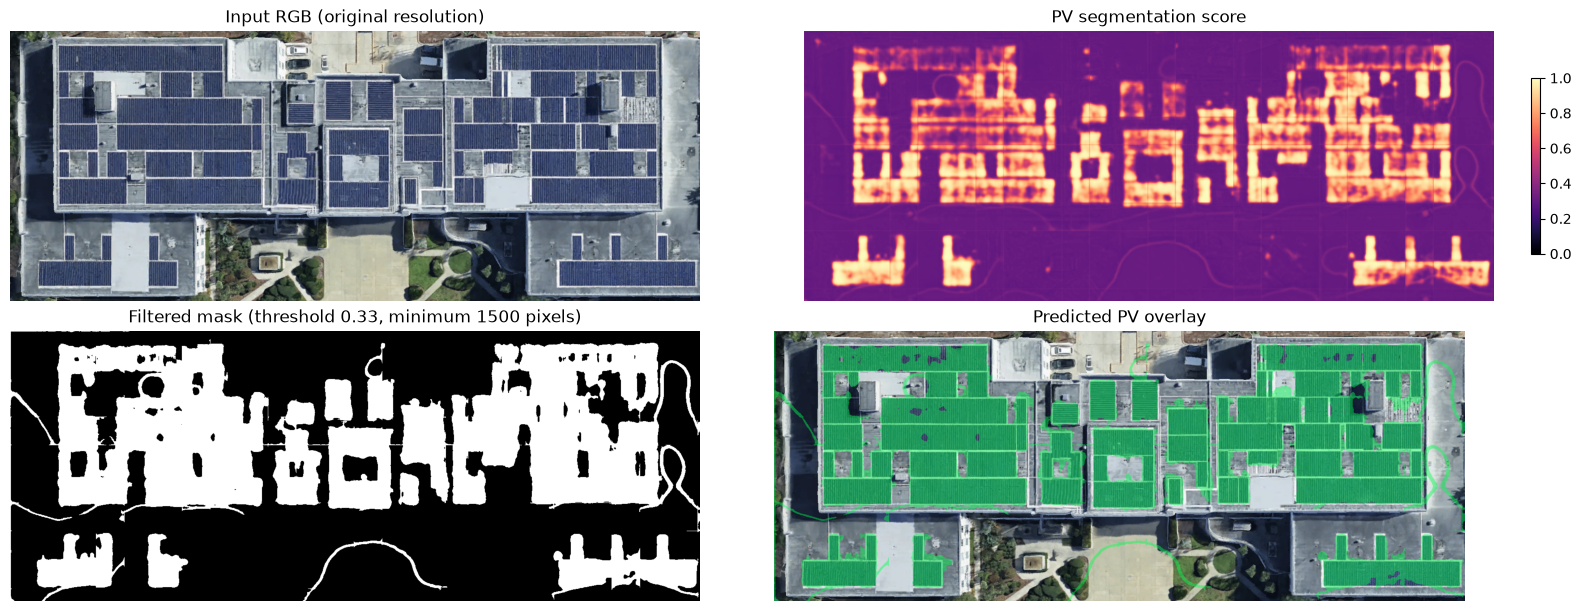

In [21]:
THRESHOLD = 0.33
MIN_COMPONENT_PIXELS = 1500  # Connected-region cutoff for the PNG; 0 disables it.
MIN_AREA_M2 = 1.0  # Projected ground-area cutoff for the optional GeoTIFF test.
if not 0 < float(THRESHOLD) < 1:
    raise ValueError("Threshold must be between 0 and 1.")
from scipy.ndimage import label
if not np.isfinite(MIN_COMPONENT_PIXELS) or MIN_COMPONENT_PIXELS < 0 or int(MIN_COMPONENT_PIXELS) != MIN_COMPONENT_PIXELS:
    raise ValueError("Minimum component size must be a finite, non-negative integer pixel count.")
raw_mask = (scores >= THRESHOLD) & (weights > 0)
# Four-neighbour connectivity matches rasterio polygonization in infer().
components, component_count = label(raw_mask)
component_sizes = np.bincount(components.ravel(), minlength=component_count + 1)
keep = component_sizes >= MIN_COMPONENT_PIXELS
keep[0] = False
mask = keep[components]
removed_regions = int(np.count_nonzero(~keep[1:]))
overlay = rgb.copy()
overlay[mask] = np.round(0.55 * rgb[mask] + 0.45 * np.array([0, 255, 80])).astype(np.uint8)
summary = {
    "image": IMAGE_PATH.name,
    "width": width,
    "height": height,
    "threshold": THRESHOLD,
    "minComponentPixels": MIN_COMPONENT_PIXELS,
    "removedRegions": removed_regions,
    "retainedRegions": component_count - removed_regions,
    "removedPixels": int(raw_mask.sum() - mask.sum()),
    "validPixels": int(valid_pixels.sum()),
    "pvPixels": int(mask.sum()),
    "pvPixelFraction": float(mask.sum() / valid_pixels.sum()),
    "maxScore": float(scores[valid_pixels].max()),
    "meanPvScore": float(scores[mask].mean()) if mask.any() else None,
}
display(pd.DataFrame([summary]))

fig, axes = plt.subplots(2, 2, figsize=(16, 6), constrained_layout=True)
axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Input RGB (original resolution)")
heatmap = axes[0, 1].imshow(np.ma.masked_where(~valid_pixels, scores), cmap="magma", vmin=0, vmax=1)
axes[0, 1].set_title("PV segmentation score")
fig.colorbar(heatmap, ax=axes[0, 1], shrink=0.65)
axes[1, 0].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title(f"Filtered mask (threshold {THRESHOLD:g}, minimum {MIN_COMPONENT_PIXELS} pixels)")
axes[1, 1].imshow(overlay)
axes[1, 1].set_title("Predicted PV overlay")
for ax in axes.flat:
    ax.axis("off")
plt.show()


## Estimate array area and system capacity

The active image is `pv2.png`. Your **bottom-left horizontal array is 18 m wide × 6 m high = 108 m²**. Its approximate image rectangle is `(64, 515, 226, 571)` in original pixels; inspect the cyan outline below and adjust it if needed. Calibration uses the measured rectangle's area divided by its pixel area. It does not assume an entire connected model region is the reference: nearby vertical strips or neighboring arrays may connect in the mask.

Calibrations are saved by image checksum. The earlier image's three-array measurements are preserved and activate only for that image; a new image without calibration still runs segmentation and exports pixels, leaving physical values empty. The source image must be rerun through segmentation after changing `IMAGE_PATH`.

The scale transfers approximately across the 3D view and is not a camera reconstruction. Predicted mask boundaries can include gaps or neighboring roof pixels. `MODULE_COVERAGE_FRACTION` defaults to 1 (the whole footprint is assumed covered by panels); lower it to account for gaps. Efficiency and tilt remain editable assumptions. Measurements are treated as projected ground footprints; if they are panel surface dimensions, use 0° tilt to avoid correcting tilt twice. Panel-equivalent counts use assumed module dimensions and are not counts of individually detected panels.

For a new image, set `REFERENCE_ARRAYS = []` and `REFERENCE_RECTANGLE = None`, then select one of the calibration methods below or add its measured rectangle under the new image checksum. Google's [Photorealistic 3D Tiles](https://developers.google.com/maps/documentation/tile/3d-tiles-overview) are rendered perspective views. The PNG contains no georeferencing or saved camera metadata; a zoom number alone cannot supply ground scale. For a roughly overhead view, use a known horizontal distance in [Google Maps](https://support.google.com/maps/answer/1628031?hl=en) and the corresponding pixel endpoints below. A single scale is only a local approximation: oblique views, different roof elevations, and resizing can change scale across the image. For better estimates, use georeferenced overhead imagery or reconstruct each roof plane from the original 3D camera/mesh.

Alternatively, set `REFERENCE_PANEL_PIXELS` to the visible pixel area of **one complete module** on the same roof plane, and use assumed module dimensions. This estimates module surface area directly, so it does not apply the tilt correction a second time. It is not a measurement of the unknown module's actual dimensions. The example defaults are **1.728 × 1.205 m** and **470 W** from the [REC Alpha Pure-RX datasheet](https://www.recgroup.com/sites/default/files/2025-04/Web_DS_REC%20Alpha%20Pure-RX_EN%20US_042025.pdf); change them for the installed panel type.

For each retained region, the notebook reports:
- Module surface area, projected ground area when available, and equivalent panel count (`module area / assumed panel area`).
- Estimated kW DC from module area × `EFFICIENCY`, matching the service's sizing method. At the default 20% efficiency, 100 m² of module surface area corresponds to 20 kW DC at 1000 W/m².
- An alternative estimate using equivalent panel count × assumed panel watts. These are separate assumptions; the example panel rating implies a higher efficiency than the service's default 20%.

Totals include all retained detections; regions may be fragments of the same installation or false positives. They do not establish separate systems, measured nameplate capacity, AC inverter capacity, energy yield, or an accuracy interval. If scale is missing, physical values stay empty. Re-run these sizing cells and the export cell after changing calibration, threshold, or region filtering.

In [22]:
# Calibrations belong to a particular image, identified by its contents.
# New images without a saved calibration can still run segmentation and pixel exports.
IMAGE_CALIBRATIONS = {
    "e681aba269ab5828e0eb61cc1458eba95d8fc9db16b0d5ea536c8be4eaea53e1": {
        "arrays": [
            {"name": "middle", "pointPixels": (503, 100), "lengthM": 33., "widthM": 10.},
            {"name": "left", "pointPixels": (54, 119), "lengthM": 30., "widthM": 15.},
            {"name": "right lower (region 4)", "pointPixels": (845, 164), "lengthM": 38., "widthM": 15.},
        ],
    },
    "6a990b84aec3320f41ed55589b272758d2cdb609db6a3401ce89b8d42721ce7a": {
        "rectangle": {
            "name": "bottom-left horizontal array",
            "boundsPixels": (64, 515, 226, 571),  # (left, top, right, bottom), original image pixels.
            "lengthM": 18.,  # Horizontal width supplied by the user.
            "widthM": 6.,  # Vertical height supplied by the user.
        },
    },
}
CURRENT_IMAGE_SHA256 = hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest()
active_calibration = IMAGE_CALIBRATIONS.get(CURRENT_IMAGE_SHA256, {})
REFERENCE_ARRAYS = active_calibration.get("arrays", [])
REFERENCE_RECTANGLE = active_calibration.get("rectangle")

# Alternative methods: first clear REFERENCE_ARRAYS and set REFERENCE_RECTANGLE = None.
METRES_PER_PIXEL = None
REFERENCE_DISTANCE_M = None
REFERENCE_LINE_PIXELS = None  # ((x0, y0), (x1, y1)) for that distance in THIS image.
REFERENCE_PANEL_PIXELS = None  # Pixel area of ONE individual module, not a whole array.

ASSUMED_PANEL_LENGTH_M = 1.728
ASSUMED_PANEL_WIDTH_M = 1.205
ASSUMED_PANEL_WATTS = 470.0
MODULE_COVERAGE_FRACTION = 1.0  # Fraction of array footprint occupied by panels (1 assumes no gaps).


Reference footprint: 18 × 6 m = 108 m².
Local projected area scale: 0.011905 m² per image pixel.


,regionId,arrayName,areaSource,pixels,centerX,centerY,meanScore,projectedAreaM2,moduleAreaM2,panelEquivalentCount,estimatedKwDc,estimatedKwDcAtAssumedPanelRating
0,region-1,region-1,local_ground_scale,314032,780.987,230.239,0.667,3738.476,3738.476,1795.411,747.695,843.843
1,region-2,region-2,local_ground_scale,5978,825.224,142.600,0.475,71.167,71.167,34.178,14.233,16.064
2,region-3,region-3,local_ground_scale,2756,891.293,354.531,0.695,32.810,32.810,15.757,6.562,7.406
3,region-4,region-4,local_ground_scale,14756,152.640,526.796,0.758,175.667,175.667,84.364,35.133,39.651
4,region-5,region-5,local_ground_scale,6743,340.788,522.694,0.787,80.274,80.274,38.552,16.055,18.119
5,region-6,region-6,local_ground_scale,23598,1372.440,529.281,0.701,280.929,280.929,134.917,56.186,63.411
6,region-7,region-7,local_ground_scale,2681,809.881,519.969,0.357,31.917,31.917,15.328,6.383,7.204


{'calibrationStatus': 'local_ground_scale',
 'retainedRegions': 7,
 'detectedPixels': 370544,
 'totals': {'projectedAreaM2': 4411.238095238095,
  'moduleAreaM2': 4411.238095238095,
  'panelEquivalentCount': 2118.506077703865,
  'estimatedKwDc': 882.2476190476191,
  'estimatedKwDcAtAssumedPanelRating': 995.6978565208163},
 'referenceArrays': [],
 'assumptions': {'metresPerPixel': None,
  'projectedPixelAreaM2': 0.011904761904761904,
  'referencePanelPixels': None,
  'assumedPanelLengthM': 1.728,
  'assumedPanelWidthM': 1.205,
  'assumedPanelAreaM2': 2.08224,
  'assumedPanelWatts': 470.0,
  'efficiency': 0.2,
  'tiltDegrees': 0.0,
  'tiltApplied': True,
  'moduleCoverageFraction': 1.0,
  'referenceArrayPixelAreaM2': None,
  'areaBasis': 'Measured references are projected ground footprints; other footprints use a transferred mask-area scale',
  'capacityBasis': 'Estimated DC at STC, not verified nameplate or AC capacity',
  'scaleScope': 'Local approximation; perspective and roof plane ch

Detected module area: 4411.2 m²; estimated DC capacity: 882.2 kW.


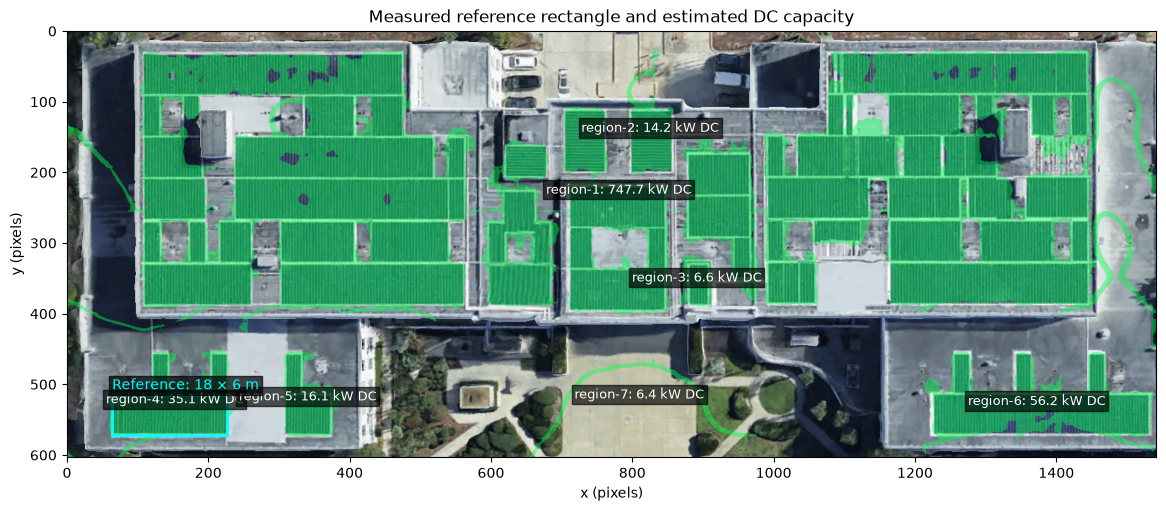

In [23]:
from scipy.ndimage import find_objects
from analysis_service.models import pv_capacity


def estimate_region_sizes(mask, scores, *, metres_per_pixel=None,
                          reference_panel_pixels=None, panel_length_m=1.728,
                          panel_width_m=1.205, panel_watts=470., efficiency=.2, tilt=0.,
                          reference_arrays=(), coverage_fraction=1., pixel_area_m2=None):
    def positive(value, name):
        value = float(value)
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"{name} must be finite and greater than zero.")
        return value

    panel_area = positive(panel_length_m, "Panel length") * positive(panel_width_m, "Panel width")
    panel_watts = positive(panel_watts, "Panel watts")
    # Validate efficiency and tilt using the same rules as production inference.
    pv_capacity(0, float(efficiency), float(tilt))
    coverage_fraction = positive(coverage_fraction, "Module coverage fraction")
    if coverage_fraction > 1:
        raise ValueError("Module coverage fraction must be at most 1.")
    if sum((metres_per_pixel is not None, reference_panel_pixels is not None, bool(reference_arrays), pixel_area_m2 is not None)) > 1:
        raise ValueError("Choose only one calibration method.")
    regions, count = label(mask)
    references = {}
    reference_area_per_pixel = None
    if reference_arrays:
        for reference in reference_arrays:
            point = np.asarray(reference["pointPixels"], dtype=float)
            if point.shape != (2,) or not np.isfinite(point).all():
                raise ValueError("Each array reference needs one finite (x, y) pixel point.")
            x, y = (int(round(value)) for value in point)
            if not 0 <= x < mask.shape[1] or not 0 <= y < mask.shape[0]:
                raise ValueError("Array reference points must lie within this image.")
            region_id = int(regions[y, x])
            if region_id == 0:
                raise ValueError(f"Reference {reference['name']} is outside the retained mask. Check the point and filtering settings.")
            if region_id in references:
                raise ValueError("Two array references match the same region; update the points or segmentation.")
            length = positive(reference["lengthM"], "Reference array length")
            width_m = positive(reference["widthM"], "Reference array width")
            pixels = int(np.count_nonzero(regions == region_id))
            references[region_id] = {
                "name": reference["name"], "regionId": f"region-{region_id}",
                "pointPixels": [x, y], "lengthM": length, "widthM": width_m,
                "projectedAreaM2": length * width_m, "maskPixels": pixels,
                "areaPerPixelM2": length * width_m / pixels,
            }
        reference_area_per_pixel = sum(r["projectedAreaM2"] for r in references.values()) / sum(r["maskPixels"] for r in references.values())
        basis = "measured_array_footprints"
    elif pixel_area_m2 is not None:
        pixel_area_m2 = positive(pixel_area_m2, "Projected pixel area")
        basis = "local_ground_scale"
    elif metres_per_pixel is not None:
        metres_per_pixel = positive(metres_per_pixel, "Metres per pixel")
        basis = "local_ground_scale"
    elif reference_panel_pixels is not None:
        reference_panel_pixels = positive(reference_panel_pixels, "Reference panel pixel area")
        basis = "assumed_reference_module"
    else:
        basis = "scale_required"

    rows = []
    for index, slices in enumerate(find_objects(regions), start=1):
        if slices is None:
            continue
        region = regions[slices] == index
        pixels = int(region.sum())
        y_slice, x_slice = slices
        ys, xs = np.nonzero(region)
        projected_area = module_area = capacity = equivalent_panels = rating_capacity = None
        area_source = basis
        array_name = references[index]["name"] if index in references else f"region-{index}"
        if basis in ("local_ground_scale", "measured_array_footprints"):
            if index in references:
                projected_area = references[index]["projectedAreaM2"]
                area_source = "supplied_array_dimensions"
            elif basis == "measured_array_footprints":
                projected_area = pixels * reference_area_per_pixel
                area_source = "transferred_reference_pixel_scale"
            else:
                projected_area = pixels * (pixel_area_m2 if pixel_area_m2 is not None else metres_per_pixel ** 2)
            sizing = pv_capacity(projected_area * coverage_fraction, float(efficiency), float(tilt))
            module_area = sizing["moduleAreaM2"]
            capacity = sizing["estimatedKwDc"]
        elif basis == "assumed_reference_module":
            # The reference calibrates MODULE SURFACE area, including local foreshortening.
            module_area = pixels / reference_panel_pixels * panel_area
            capacity = module_area * float(efficiency)
        if module_area is not None:
            equivalent_panels = module_area / panel_area
            rating_capacity = equivalent_panels * panel_watts / 1000.
        rows.append({
            "regionId": f"region-{index}", "arrayName": array_name, "areaSource": area_source, "pixels": pixels,
            "centerX": float(xs.mean() + x_slice.start),
            "centerY": float(ys.mean() + y_slice.start),
            "meanScore": float(scores[slices][region].mean()),
            "projectedAreaM2": projected_area, "moduleAreaM2": module_area,
            "panelEquivalentCount": equivalent_panels, "estimatedKwDc": capacity,
            "estimatedKwDcAtAssumedPanelRating": rating_capacity,
        })
    columns = ["regionId", "arrayName", "areaSource", "pixels", "centerX", "centerY", "meanScore", "projectedAreaM2",
               "moduleAreaM2", "panelEquivalentCount", "estimatedKwDc", "estimatedKwDcAtAssumedPanelRating"]
    table = pd.DataFrame(rows, columns=columns)
    physical_keys = ["projectedAreaM2", "moduleAreaM2", "panelEquivalentCount",
                     "estimatedKwDc", "estimatedKwDcAtAssumedPanelRating"]
    totals = {
        "calibrationStatus": basis,
        "retainedRegions": count,
        "detectedPixels": int(mask.sum()),
        "totals": {key: (sum(row[key] for row in rows) if basis != "scale_required" and
                         (key != "projectedAreaM2" or basis in ("local_ground_scale", "measured_array_footprints")) else None)
                   for key in physical_keys},
        "referenceArrays": list(references.values()),
        "assumptions": {
            "metresPerPixel": metres_per_pixel,
            "projectedPixelAreaM2": pixel_area_m2,
            "referencePanelPixels": reference_panel_pixels,
            "assumedPanelLengthM": float(panel_length_m),
            "assumedPanelWidthM": float(panel_width_m),
            "assumedPanelAreaM2": panel_area,
            "assumedPanelWatts": panel_watts,
            "efficiency": float(efficiency), "tiltDegrees": float(tilt),
            "tiltApplied": basis in ("local_ground_scale", "measured_array_footprints"),
            "moduleCoverageFraction": coverage_fraction,
            "referenceArrayPixelAreaM2": reference_area_per_pixel,
            "areaBasis": "Measured references are projected ground footprints; other footprints use a transferred mask-area scale",
            "capacityBasis": "Estimated DC at STC, not verified nameplate or AC capacity",
            "scaleScope": "Local approximation; perspective and roof plane changes are not corrected",
            "buildingAssociation": "Not inferred; regions are not independent systems",
        },
    }
    return table, totals


if CURRENT_IMAGE_SHA256 != inference_image_sha256:
    raise ValueError("The selected image changed after segmentation. Re-run the image configuration and tiled segmentation cells first.")

local_scale = METRES_PER_PIXEL
local_pixel_area = None
if REFERENCE_RECTANGLE is not None:
    if (REFERENCE_ARRAYS or METRES_PER_PIXEL is not None or REFERENCE_PANEL_PIXELS is not None
            or REFERENCE_DISTANCE_M is not None or REFERENCE_LINE_PIXELS is not None):
        raise ValueError("Use only one scale-calibration method.")
    bounds = np.asarray(REFERENCE_RECTANGLE["boundsPixels"], dtype=float)
    if bounds.shape != (4,) or not np.isfinite(bounds).all():
        raise ValueError("Reference bounds must be four finite pixel coordinates: left, top, right, bottom.")
    left, top, right, bottom = bounds
    if not (0 <= left < right <= width and 0 <= top < bottom <= height):
        raise ValueError("Reference rectangle must have positive width/height and lie within this image.")
    reference_length = float(REFERENCE_RECTANGLE["lengthM"])
    reference_width = float(REFERENCE_RECTANGLE["widthM"])
    if not np.isfinite([reference_length, reference_width]).all() or min(reference_length, reference_width) <= 0:
        raise ValueError("Reference dimensions must be finite and positive.")
    # Use the measured rectangle geometry, independent of segmentation and neighboring regions.
    local_pixel_area = reference_length * reference_width / ((right - left) * (bottom - top))
    print(f"Reference footprint: {reference_length:g} × {reference_width:g} m = {reference_length * reference_width:g} m².")
    print(f"Local projected area scale: {local_pixel_area:.6f} m² per image pixel.")

if REFERENCE_DISTANCE_M is not None or REFERENCE_LINE_PIXELS is not None:
    if REFERENCE_DISTANCE_M is None or REFERENCE_LINE_PIXELS is None:
        raise ValueError("Provide both the known distance and its two image endpoints.")
    if METRES_PER_PIXEL is not None or REFERENCE_PANEL_PIXELS is not None or REFERENCE_ARRAYS or REFERENCE_RECTANGLE is not None:
        raise ValueError("Use only one scale-calibration method.")
    endpoints = np.asarray(REFERENCE_LINE_PIXELS, dtype=float)
    if endpoints.shape != (2, 2) or not np.isfinite(endpoints).all():
        raise ValueError("Reference endpoints must be two finite (x, y) pixel coordinates.")
    if np.any(endpoints < 0) or np.any(endpoints[:, 0] >= width) or np.any(endpoints[:, 1] >= height):
        raise ValueError("Reference endpoints must lie within this image.")
    pixel_distance = float(np.linalg.norm(endpoints[1] - endpoints[0]))
    if pixel_distance == 0 or not np.isfinite(REFERENCE_DISTANCE_M) or REFERENCE_DISTANCE_M <= 0:
        raise ValueError("Reference distance and endpoint separation must be greater than zero.")
    local_scale = float(REFERENCE_DISTANCE_M) / pixel_distance

array_sizing, system_sizing = estimate_region_sizes(
    mask, scores, metres_per_pixel=local_scale, reference_panel_pixels=REFERENCE_PANEL_PIXELS,
    panel_length_m=ASSUMED_PANEL_LENGTH_M, panel_width_m=ASSUMED_PANEL_WIDTH_M,
    panel_watts=ASSUMED_PANEL_WATTS, efficiency=EFFICIENCY, tilt=TILT_DEGREES,
    reference_arrays=REFERENCE_ARRAYS, coverage_fraction=MODULE_COVERAGE_FRACTION,
    pixel_area_m2=local_pixel_area,
)
system_sizing["assumptions"].update(
    referenceDistanceM=REFERENCE_DISTANCE_M,
    referenceLinePixels=REFERENCE_LINE_PIXELS,
    referenceRectangle=REFERENCE_RECTANGLE,
    calibrationImageSha256=CURRENT_IMAGE_SHA256,
)
if system_sizing["referenceArrays"]:
    display(pd.DataFrame(system_sizing["referenceArrays"]).round(4))
display(array_sizing.round(3))
display(system_sizing)
if system_sizing["calibrationStatus"] == "scale_required":
    print("Scale required: physical array size and kW DC cannot be inferred from this PNG yet.")
else:
    total = system_sizing["totals"]
    print(f"Detected module area: {total['moduleAreaM2']:.1f} m²; estimated DC capacity: {total['estimatedKwDc']:.1f} kW.")

fig, ax = plt.subplots(figsize=(16, 5), constrained_layout=True)
ax.imshow(overlay)
for row in array_sizing.itertuples():
    capacity_label = f"{row.regionId}: {row.estimatedKwDc:.1f} kW DC" if pd.notna(row.estimatedKwDc) else row.regionId
    ax.annotate(capacity_label, (row.centerX, row.centerY), color="white", fontsize=9,
                ha="center", bbox={"facecolor": "black", "alpha": .65, "pad": 2})
if REFERENCE_RECTANGLE is not None:
    from matplotlib.patches import Rectangle
    ax.add_patch(Rectangle((left, top), right - left, bottom - top, fill=False, edgecolor="cyan", linewidth=2))
    ax.text(left, top - 8, f"Reference: {reference_length:g} × {reference_width:g} m", color="cyan",
            bbox={"facecolor": "black", "alpha": .7, "pad": 2})
    ax.set_title("Measured reference rectangle and estimated DC capacity")
elif REFERENCE_LINE_PIXELS is not None:
    ax.plot(endpoints[:, 0], endpoints[:, 1], color="cyan", marker="o")
    ax.set_title(f"Sizing regions and reference distance ({REFERENCE_DISTANCE_M:g} m)")
else:
    ax.set_title("Array footprint calibration and estimated DC capacity" if REFERENCE_ARRAYS else "Retained sizing regions — image coordinates in pixels")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")
plt.show()

## Save visual test outputs
Exports go to the ignored `.analysis-data/notebook-pv/` directory. The float32 score array lets you inspect or re-threshold predictions later. These pixel outputs have no geographic area or capacity units.

Per-region sizing CSV and JSON totals include the calibration inputs and assumptions. Physical values remain empty until scale is supplied.

In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
run_name = f"{IMAGE_PATH.stem}-threshold-{THRESHOLD:g}-min-{MIN_COMPONENT_PIXELS}px"
np.save(OUTPUT_DIR / f"{IMAGE_PATH.stem}-scores.npy", scores)
Image.fromarray(mask.astype(np.uint8) * 255).save(OUTPUT_DIR / f"{run_name}-mask.png")
Image.fromarray(overlay).save(OUTPUT_DIR / f"{run_name}-overlay.png")
(OUTPUT_DIR / f"{run_name}-summary.json").write_text(json.dumps({
    **summary,
    "imagePath": str(IMAGE_PATH),
    "imageSha256": hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest(),
    "modelVersion": card.get("version"),
    "checkpointSha256": checkpoint_sha256,
    "georeferenced": False,
    "inferenceSeconds": inference_seconds,
}, indent=2))
print(f"Saved scores, mask, overlay, and summary to {OUTPUT_DIR}")

array_sizing.to_csv(OUTPUT_DIR / f"{run_name}-sizing.csv", index=False)
(OUTPUT_DIR / f"{run_name}-sizing.json").write_text(json.dumps({
    **system_sizing,
    "regions": json.loads(array_sizing.to_json(orient="records")),
    "threshold": THRESHOLD, "minComponentPixels": MIN_COMPONENT_PIXELS,
    "imageSha256": hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest(),
    "checkpointSha256": checkpoint_sha256, "modelVersion": card.get("version"),
}, indent=2, allow_nan=False))
print("Saved per-region sizing CSV and sizing assumptions/totals JSON.")


Saved scores, mask, overlay, and summary to /Users/admin/git/tidebound/.analysis-data/notebook-pv
Saved per-region sizing CSV and sizing assumptions/totals JSON.


## Optional: test the production GeoTIFF workflow

Set `GEOTIFF_PATH` in the configuration cell, then re-run that cell and this one. The service requires georeferenced 8-bit RGB imagery with ground sample distance ≤ 0.6 m and ≤ 25 million pixels. Use an AOI crop for a quick CPU test.
`infer()` returns WGS84 PV polygons, area/capacity rows, the model card, and assumptions.
The PNG above cannot be passed to it without real georeferencing; do not invent a CRS or pixel size.


In [9]:
geo_result = None
if GEOTIFF_PATH is None:
    print("Skipped: set GEOTIFF_PATH to test production infer() on a georeferenced RGB image.")
else:
    from analysis_service.rasters import raster_metadata
    geotiff = repo_path(GEOTIFF_PATH)
    display(raster_metadata(geotiff))
    geo_started = time.perf_counter()
    geo_result = infer(
        geotiff, CHECKPOINT, MODEL_CARD,
        efficiency=EFFICIENCY, tilt=TILT_DEGREES, threshold=THRESHOLD, min_area_m2=MIN_AREA_M2,
    )
    rows = pd.DataFrame(geo_result["rows"])
    print(f"Detected {len(rows)} PV polygons in {time.perf_counter() - geo_started:.2f} s.")
    display(rows)
    display(geo_result["assumptions"])
    display(geo_result["filtering"])
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    geo_name = f"{geotiff.stem}-threshold-{THRESHOLD:g}-min-{MIN_AREA_M2:g}m2"
    (OUTPUT_DIR / f"{geo_name}.geojson").write_text(json.dumps(geo_result["data"], indent=2))
    (OUTPUT_DIR / f"{geo_name}-result.json").write_text(json.dumps(geo_result, indent=2))
    rows.to_csv(OUTPUT_DIR / f"{geo_name}-rows.csv", index=False)
    print(f"Saved GeoJSON, full result, and CSV to {OUTPUT_DIR}")


Skipped: set GEOTIFF_PATH to test production infer() on a georeferenced RGB image.
